# Face detection, expression and identity: trained end to end on Colab

This notebook trains three neural networks from open data, tests each one, and saves them in a form that runs on an ordinary laptop CPU:

1. **Detector.** It finds every face in a photo and five landmark points on each face: the two eyes, the nose tip and the two corners of the mouth. It follows the design of CenterFace, a published detector that finds each face by predicting the point at its centre. Its backbone, the main part of the network, is a ResNet-18 that starts from general ImageNet weights. The backbone turns the photo into feature maps, grids of numbers that describe each region of the photo, and a small head on top reads those maps and predicts where the face centres are. The detector is trained on WIDER FACE, a set of real web photos of crowds and events.
2. **Expression.** It says which of eight expressions a face shows. It is a ConvNeXt-Tiny classifier, also started from ImageNet weights, and fine-tuned on EmoNet-Face, a set of AI-generated portraits labelled by experts. Each portrait is first cut out and turned upright using our own detector's landmarks.
3. **Identity.** It turns a face into an embedding, a list of 512 numbers, and the embeddings of two photos of the same person point in almost the same direction. The network is an IResNet, a ResNet variant built for face recognition, trained from random weights on DigiFace-1M, a set of synthetic faces rendered from 3D models. Its training uses a CosFace margin: the score for the correct person is lowered by a fixed amount, so the network has to separate different people by a wider gap.

No network that was already trained on faces is used. Every dataset and its licence are recorded in a manifest in section 2. The model card in section 10 also records the licences of the four training sources: WIDER FACE, the RetinaFace annotations, DigiFace-1M and EmoNet-Face.

**How to run it.** The notebook needs a Colab machine with an NVIDIA GPU. With `MODE = "smoke"`, the default, every cell runs on small slices of each dataset. That tests the whole notebook quickly, but the models it produces are not useful. With `MODE = "full"` it is the real run. The run that produced the current models took 64 minutes on an A100, with budgets of 40 minutes for the detector, 50 for identity and 12 for expression, so the larger default budgets in the next cell make a longer run. Most sections run checks that print PASS or FAIL, and the last cell prints ALL CHECKS PASSED when every check held. Without a Google Drive mount, everything the run writes stays on the Colab machine and is lost when the server is removed, so download what you want to keep first.

## How the pipeline fits together

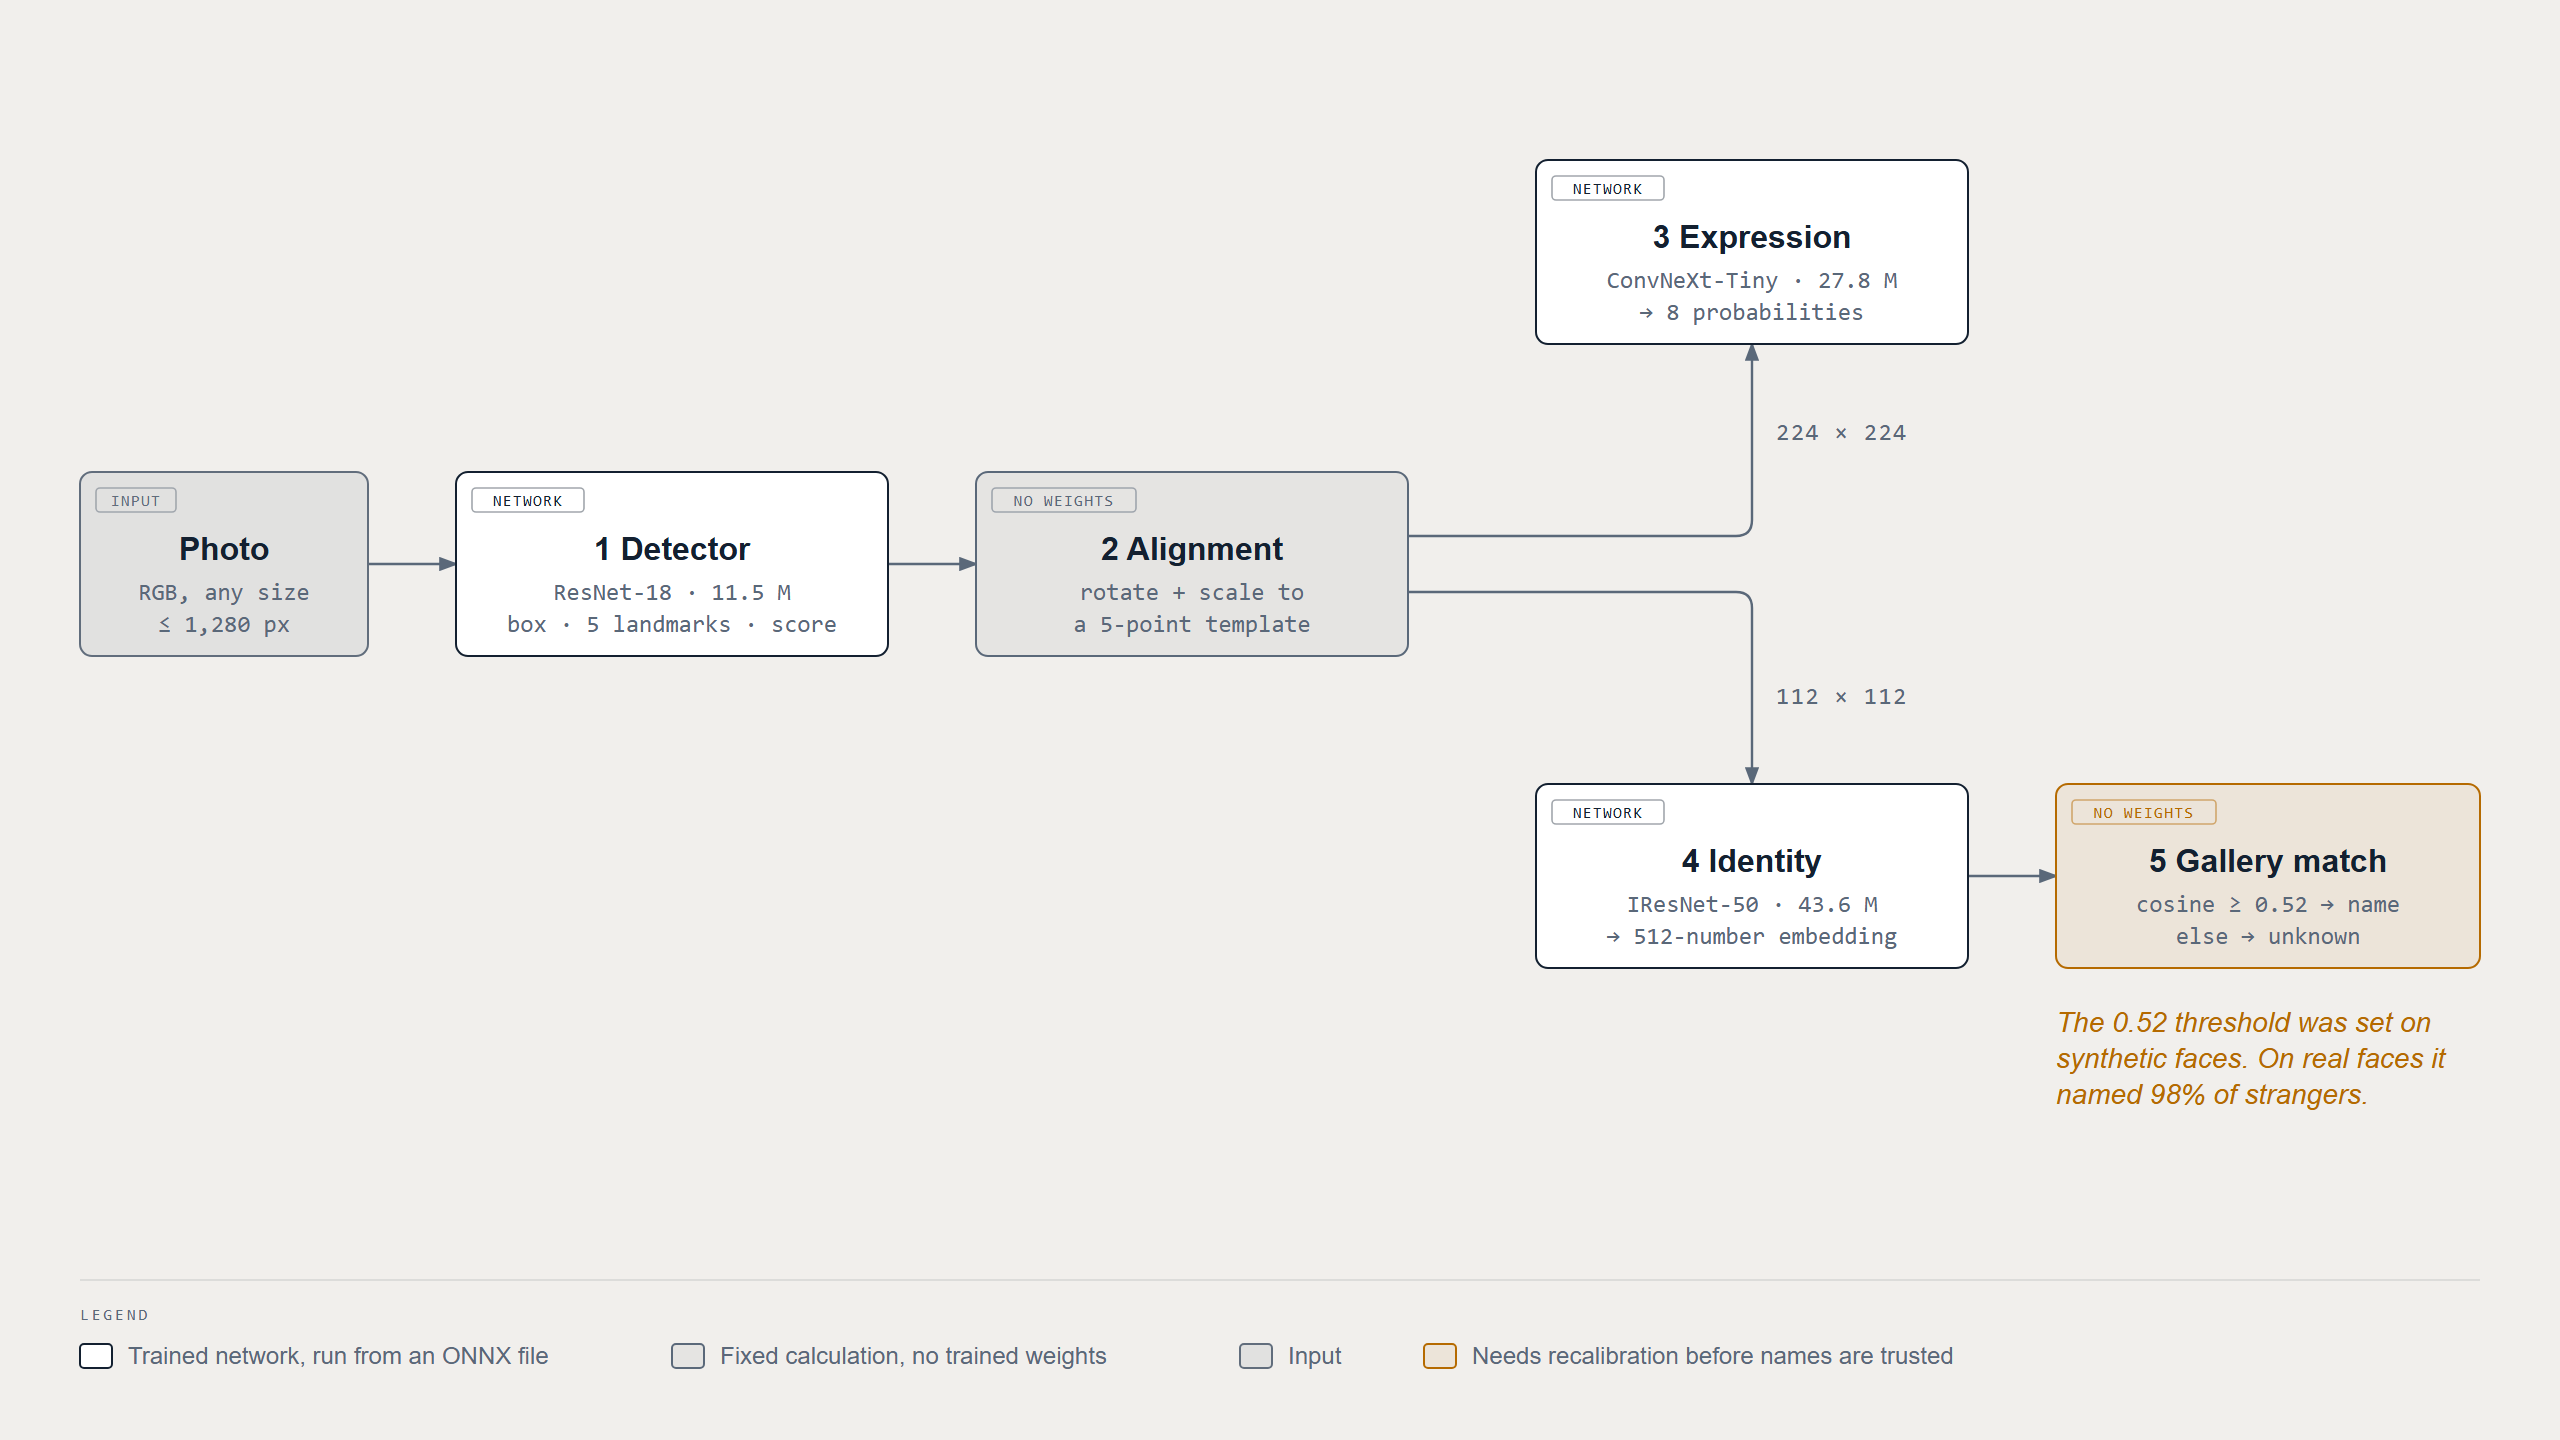

The figure shows what happens to one photo once the models are trained, when the finished pipeline runs on a laptop or a GPU. The detector finds each face and its five landmarks. The alignment step uses those landmarks to cut two upright crops of the face. The larger crop goes to the expression model and the smaller one to the identity model, whose embedding is compared with the people enrolled in the gallery. Boxes with a white fill are the three trained networks, which this notebook trains, and grey boxes are fixed calculations with no trained weights. The figure's source and a PNG copy are in `docs/figures/`.

| Block | Model | Input | Output |
|---|---|---|---|
| 1. Detector | CenterFace-style network on a ResNet-18 backbone, 11.5 million weights | the photo, shrunk so its longest side is at most 1,280 pixels | for each face, a box, five landmarks (eyes, nose tip, mouth corners) and a confidence score; faces below the score threshold (0.32 in the current models) or smaller than 16 pixels are dropped |
| 2. Alignment | none: a rotation and scaling | the photo and each face's five landmarks | an upright crop of each face at 224 by 224 and at 112 by 112 pixels |
| 3. Expression | ConvNeXt-Tiny, 27.8 million weights | the 224 by 224 crop | eight probabilities: neutral, happy, sad, surprise, fear, disgust, anger and contempt |
| 4. Identity | IResNet-50, 43.6 million weights | the 112 by 112 crop and its mirror image | an embedding of 512 numbers |
| 5. Gallery match | none: a comparison | the embedding | the closest enrolled person's name when the cosine similarity reaches the threshold (0.52 in the current models), otherwise "unknown" |

Sections 3 to 9 prepare the data, train the three networks and test them. Section 10 exports them to ONNX files, and section 11 runs this whole pipeline on photos. The 0.52 naming threshold was set on synthetic faces, and on real faces it gave a name to 98% of strangers, so it needs recalibrating before any name is trusted.

## Parameters

The next cell holds the seven settings of a run. `MODE` chooses smoke or full. `EXP` and `RUN_ID` name the folder the results go into, for example `scratch/smoke-001` for a smoke run or `exp-001/run-003` for the real run that produced the current models. The three budgets set how many minutes each training is planned to take. Each training measures its own speed first and plans its epochs, the full passes over its training data, to fit its budget. The detector and identity trainings stop at their budgets, and the expression training may run up to 1.3 times its budget. `USE_DRIVE` keeps the downloaded files in Google Drive, so that they are downloaded only once (section 2). Papermill is a tool that runs a notebook from top to bottom as an ordinary program. When it runs this notebook unattended, it finds this cell by its tag `parameters` and replaces these values. To run the notebook by hand, change `MODE` here before you start. For a full run, also give `EXP` and `RUN_ID` new values, such as `exp-001` and `run-004`, so that the run writes into its own folder and does not reuse the plans of an earlier run.

In [ ]:
# Parameters (papermill overrides these).
MODE = "smoke"            # "smoke": tiny subsets to test every cell; "full": the real run
EXP = "scratch"           # exp-NNN for a real run, scratch for a smoke run
RUN_ID = "smoke-001"      # run-NNN or smoke-NNN
DET_BUDGET_MIN = 50.0     # minutes for detector training
ID_BUDGET_MIN = 55.0      # minutes for identity training (a second process on the same GPU)
EXPR_BUDGET_MIN = 12.0    # minutes for expression training
USE_DRIVE = True          # keep the downloaded files in Google Drive (Colab asks you to approve it once)

## 1. Setup

**Get the code onto the machine.** This cell matters only when the notebook runs on a Colab kernel opened from VS Code or the browser, and it does nothing on a laptop. Colab gives every new server an empty disk, so the project's code has to be copied onto each new server. The cell first checks that the machine has an NVIDIA GPU, by looking for the `nvidia-smi` program that NVIDIA's driver installs. If there is none, it stops at once with a message, because a TPU or CPU machine cannot run this notebook. It then copies this project's public GitHub repository to `/content/face-detection-classification`, unless a copy is already there. A good result is that the cell finishes in a few seconds without an error.

In [ ]:
# Bootstrap for a Colab kernel opened from VS Code or the browser. It does nothing on this laptop.
# On a Colab machine it stops at once without an NVIDIA GPU, and it clones the code when the clone is missing.
import os, shutil, subprocess
REPO_URL = "https://github.com/ekmungi/face-detection-classification"
COLAB_CLONE = "/content/face-detection-classification"
if os.path.isdir("/content"):              # a Colab machine: the same test that paths.py uses
    if shutil.which("nvidia-smi") is None:
        raise RuntimeError(
            "This notebook needs a Colab GPU machine (T4, L4 or A100), and this machine has no NVIDIA GPU "
            "(it is a TPU or CPU machine). Remove this server (Ctrl+Shift+P, Colab: Remove Server) and start "
            "a new one with GPU.")
    if not os.path.isdir(COLAB_CLONE):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, COLAB_CLONE], check=True)

**Load the project and prepare the run.** This cell lets Python load the copied code. It installs ONNX, the library that saves models in the ONNX file format, and ONNX Runtime, the library that later runs those files on a CPU, if either is missing. It then loads the project's modules, picks the GPU and creates the run folder with `figures/` and `models/` inside it. It also defines two helpers that later cells use. `check()` prints PASS or FAIL together with the number it measured, and it keeps a list for the final summary. `savefig()` saves each figure into the run folder and shows it. Look at the first line the cell prints: it should say `device=cuda` and name the GPU, for example `gpu=NVIDIA L4`. The last line gives the code version, the Git commit the run uses, so that every result can be traced to the exact code.

In [ ]:
import os, sys, json, time, subprocess, shutil, hashlib, platform
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor

REPO = Path(os.environ.get("FACEKIT_REPO", "/content/face-detection-classification"))
if not REPO.exists():
    REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(REPO)
sys.path.insert(0, str(REPO))
try:
    import onnx, onnxruntime  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "onnx", "onnxruntime"], check=True)

import numpy as np, torch, cv2, matplotlib
import matplotlib.pyplot as plt
import paths, runlib
from facekit import (align, arrays, datasets, det_eval, engine, export, metrics, prepare, sources)
from facekit.det_data import parse_retinaface_labels, parse_wider_official, WiderFaceTrain, detection_collate
from facekit.det_model import FaceDetNet, detection_loss, detect_image
from facekit.det_task import DetectorTask, split_records, predict_records, choose_score_threshold
from facekit.detect import FaceDetector
from facekit.expression import CLASSES, ExpressionNet
from facekit.identity import IdentityTrainer, IResNet
from facekit.tasks import ExpressionTask, IdentityTask, embed, predict_logits
from facekit.gallery import Gallery
from facekit.pipeline import FaceAnalyzer, softmax

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True
SMOKE = MODE == "smoke"
CPUS = os.cpu_count() or 2
RUN = paths.run_dir(EXP, RUN_ID)
RUN.mkdir(parents=True, exist_ok=True)
FIG = RUN / "figures"; FIG.mkdir(exist_ok=True)
MODELS = RUN / "models"; MODELS.mkdir(exist_ok=True)
DATA = paths.work_data_dir(); RAW = DATA / "raw"; ARR = DATA / "arrays" / MODE   # smoke and full never share arrays
RAW.mkdir(parents=True, exist_ok=True); ARR.mkdir(parents=True, exist_ok=True)
SUMMARY = {"mode": MODE, "run": str(RUN), "started": time.strftime("%Y-%m-%d %H:%M:%S")}
CHECKS = []

def check(name, ok, detail=""):
    CHECKS.append({"check": name, "ok": bool(ok), "detail": str(detail)})
    print(("PASS" if ok else "FAIL"), "-", name, "-", detail)

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", bbox_inches="tight"); plt.show()

gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none"
print(f"mode={MODE} device={DEVICE} gpu={gpu} cpus={CPUS} torch={torch.__version__} cv2={cv2.__version__}")
print("run folder:", RUN); print("data folder:", DATA)
print("code version:", runlib.read_code_version(REPO))
SUMMARY.update({"gpu": gpu, "cpus": CPUS, "code_version": runlib.read_code_version(REPO)})

**Choose the amount of data for this mode.** Both modes run exactly the same cells, and only the amount of data and the number of training steps differ. DigiFace-1M comes in parts, archives of 2,000 synthetic identities each. Smoke mode trains the identity model on at most 300 identities of one part and tests it on 100 identities of another. It uses 600 WIDER training photos and 120 WIDER validation photos, at most 600 portraits from one EmoNet-Face Binary file and 120 from one HQ file, and a few dozen training steps per model. Full mode trains on two DigiFace parts and tests on a third. It uses all of WIDER FACE, all five EmoNet-Face Binary files and two of the seven HQ files, and it trains each model for its planned epochs or until its time budget runs out, whichever comes first. The cell also decides how many CPU processes load data for each training. The detector gets most of them, because it decodes JPEG photos as it trains, and the identity model gets two or three, because it reads images that are already decoded. Read the printed configuration to confirm the mode before the long cells start.

In [ ]:
# The configuration of each mode. The smoke run uses tiny subsets of the same data as the full run.
CFG = {
    "smoke": dict(digiface_train=["0-1999"], digiface_test="8000-9999", id_max_ids=300, id_val_ids=60, id_max_per_id=24,
                  id_test_ids=100, emonet_files=1, emonet_max=600, hq_files=1, hq_max=120, wider_train_max=600,
                  wider_val_max=120, det_max_steps=60, expr_max_steps=40, id_max_steps=80, id_depth="iresnet18"),
    "full": dict(digiface_train=["0-1999", "2000-3999"], digiface_test="8000-9999", id_max_ids=None, id_val_ids=400,
                 id_max_per_id=None, id_test_ids=500, emonet_files=5, emonet_max=None, hq_files=2, hq_max=None,
                 wider_train_max=None, wider_val_max=None, det_max_steps=0, expr_max_steps=0, id_max_steps=0,
                 id_depth="auto"),
}[MODE]
WORKERS_DET = max(2, CPUS - 4)       # the detector's JPEG decoding needs most of the CPU
WORKERS_ID = 2 if CPUS <= 8 else 3   # identity reads pre-decoded arrays, so it needs few workers
print(json.dumps(CFG, indent=1)); print("workers: detector", WORKERS_DET, "identity", WORKERS_ID)
SUMMARY["config"] = CFG

## 2. Data: download every dataset and record its licence

**Get and unpack the datasets.** On Colab with `USE_DRIVE = True`, this cell first mounts Google Drive, which shows a Google page that you must approve within two minutes. The downloaded files then live in the artifacts folder's `data/raw` in Drive, so a file downloaded once is found there by every later machine and is not downloaded again. Each file that is missing is downloaded straight into that folder, up to six at a time. The cell checks each file's size where the project records it and tries each download up to four times in total. The zip archives are unpacked onto the machine's own disk, in `/content/data/raw`, because unpacking the 288,000 DigiFace images into Drive would be slow and would sync them to the laptop. The Face Research Lab London Set is downloaded onto the machine only and never goes to Drive. If Drive is not mounted, as in an unattended run, every file is downloaded onto the machine. Smoke mode needs about 8.7 GB of files. Downloading them takes about 13 minutes, because Microsoft's DigiFace server is slow, about 5 MB/s for each file, while reading them from Drive is several times faster. The cell prints where the files live and where they are unpacked, then a line for each dataset as soon as it is done, saying whether it was downloaded or already there. Every 30 seconds it also prints a progress line that names what is still downloading or unpacking, how many gigabytes have arrived and the current speed, so a long wait shows steady progress. If you stop the cell, it ends within a few seconds, keeps every finished download and says how many are complete, and running the cell again continues with the rest. The cell then writes `data_manifest.json`, which lists every source with its address, its licence and the number of images unpacked from each archive, and it prints the licence of each source. The parquet and text files are recorded with a count of zero, because they are not unpacked. A good result is a line for every dataset with a size above zero. The Face Research Lab London Set is downloaded only for one expression check in section 8, and this notebook never uses it to identify anyone.

In [ ]:
LONDON = [sources.LONDON_NEUTRAL, sources.LONDON_SMILING]
WIDER_SPLIT = datasets.Source(name="wider_split", url=f"{sources.HF}/CUHK-CSE/wider_face/resolve/main/data/wider_face_split.zip",
                              filename="wider_face_split.zip", licence=sources.WIDER_LICENCE, licence_url=sources.WIDER_LICENCE_URL)
WANTED = ([sources.WIDER_TRAIN, sources.RETINAFACE_LABELS, sources.WIDER_VAL, WIDER_SPLIT]
          + sources.EMONET_BINARY[:CFG["emonet_files"]] + sources.EMONET_HQ[:CFG["hq_files"]]
          + [sources.digiface_part(p) for p in CFG["digiface_train"] + [CFG["digiface_test"]]] + LONDON)

# Six downloads at a time. A line appears as each dataset finishes and a progress line every 30 seconds. The stop
# button ends the cell within seconds: finished downloads are kept, and running the cell again continues.
# Where the downloaded files live. On Colab with USE_DRIVE, that is the artifacts folder's data/raw in Google Drive,
# so a file downloaded once is there for every later machine. Archives are unpacked onto this machine's own disk
# (RAW), and the London photos never leave this machine.
ARCHIVES = RAW
if os.path.isdir("/content") and USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")            # approve the Google page within two minutes
        found = paths.drive_artifacts_dir()
        if found is not None:
            ARCHIVES = found / "data" / "raw"
            ARCHIVES.mkdir(parents=True, exist_ok=True)
    except Exception as error:                   # no approval, or the folder is not in Drive: use this machine
        print("Google Drive is not used, so the files are downloaded onto this machine:", error)
        ARCHIVES = RAW
print("downloaded files:", ARCHIVES)
print("unpacked folders:", RAW)
started = time.time()
fetched = datasets.fetch_all(WANTED, ARCHIVES, extract_root=RAW, local_names={s.name for s in LONDON},
                             workers=6, retries=4, report_every=30)
FILES = {record["name"]: Path(record["path"]) for record in fetched}
print(f"all downloads and extractions: {time.time() - started:.0f} s")
manifest = datasets.write_manifest(RUN / "data_manifest.json", WANTED, {s.name: datasets.count_images(RAW / s.name) for s in WANTED})
print(f"{'dataset':22s} licence"); [print(f"{s['name']:22s} {s['licence']}") for s in manifest["sources"]]
SUMMARY["datasets"] = [{"name": s["name"], "licence": s["licence"], "url": s["url"]} for s in manifest["sources"]]

**Check the third-party copies against the official boxes.** Two files come from copies that other people uploaded to Hugging Face. One holds the landmark annotations that the authors of the RetinaFace detector made for the WIDER training photos. The other is a parquet file, a compressed table format, of the WIDER validation photos. A copy can have been altered or shifted, so this cell compares their face boxes with the official WIDER FACE box lists, photo by photo, allowing one pixel of difference. A good result is two PASS lines with at least 97% of the photos agreeing. In the full run the RetinaFace labels matched in 12,880 of 12,880 photos, and the validation copy matched in 398 of the 400 photos checked.

In [ ]:
# Integrity checks: the third-party mirrors must agree with the official WIDER FACE boxes.
split_dir = next((RAW / "wider_split").rglob("wider_face_train_bbx_gt.txt")).parent
official_train = {Path(r["path"]).name: r for r in parse_wider_official(split_dir / "wider_face_train_bbx_gt.txt")}
official_val = {Path(r["path"]).name: r for r in parse_wider_official(split_dir / "wider_face_val_bbx_gt.txt")}
retina = parse_retinaface_labels(FILES["retinaface_labels"])

def boxes_match(a, b, tol=1.0):
    a = np.asarray(a).reshape(-1, 4); b = np.asarray(b).reshape(-1, 4)
    b = b[(b[:, 2] > b[:, 0]) & (b[:, 3] > b[:, 1])]
    if len(a) != len(b): return False
    return bool(np.all(np.abs(np.sort(a, axis=0) - np.sort(b, axis=0)) <= tol))

matched = sum(boxes_match(r["boxes"], official_train[Path(r["path"]).name]["boxes"]) for r in retina if Path(r["path"]).name in official_train)
share = matched / max(1, len(retina))
check("RetinaFace labels agree with official WIDER train boxes", share >= 0.97, f"{matched}/{len(retina)} images ({share:.1%})")
n_val_checked = n_val_ok = 0
for rec in prepare.wider_val_records(FILES["wider_val"], max_items=400):
    key = Path(rec["path"]).name
    if key in official_val:
        n_val_checked += 1; n_val_ok += boxes_match(rec["boxes"], official_val[key]["boxes"])
check("WIDER validation parquet agrees with official boxes", n_val_ok >= 0.97 * max(1, n_val_checked), f"{n_val_ok}/{n_val_checked} images")

## 3. Identity data: DigiFace-1M arrays, split by identity

**Prepare the identity images and split them by person.** DigiFace-1M provides 72 images for each synthetic identity. This cell decides which identities are used for training, which are held back for validation to choose the thresholds, and which are kept for the final test. It splits by identity, so that all the images of one person stay in one group. It also takes the test identities from a separate DigiFace part, identities 8000 to 9999. It then decodes the PNG images once into arrays on disk, so that training does not decode image files on every pass. Look for two PASS lines, which confirm that no identity is shared between the groups, and a figure with eight images each of three identities. The figure shows what the identity model learns from: the same rendered face in different poses and lighting.

In [ ]:
id_paths, id_names = [], []
for part in CFG["digiface_train"]:
    p, n = prepare.digiface_records(RAW / f"digiface_{part}"); id_paths += p; id_names += n
train_ids, val_ids = prepare.split_identities(id_names, CFG["id_val_ids"], seed=0, max_ids=CFG["id_max_ids"])
label_of = {name: i for i, name in enumerate(train_ids + val_ids)}       # training identities first
test_paths, test_names = prepare.digiface_records(RAW / f"digiface_{CFG['digiface_test']}")
test_ids = sorted(set(test_names))[: CFG["id_test_ids"]]
test_label = {name: i for i, name in enumerate(test_ids)}
started = time.time()
if not arrays.array_exists(ARR, "digiface_train"):
    prepare.build_digiface_array(id_paths, id_names, train_ids + val_ids, ARR, "digiface_train", label_of,
                                 max_per_id=CFG["id_max_per_id"], workers=CPUS, extra_meta={"num_train_ids": len(train_ids)})
if not arrays.array_exists(ARR, "digiface_test"):
    prepare.build_digiface_array(test_paths, test_names, test_ids, ARR, "digiface_test", test_label, workers=CPUS)
id_images, id_labels, id_desc = arrays.read_array(ARR, "digiface_train")
test_images, test_labels, test_desc = arrays.read_array(ARR, "digiface_test")
print(f"arrays ready in {time.time() - started:.0f} s: train+val {len(id_labels)} images, test {len(test_labels)} images")
print(f"identities: train {len(train_ids)}, validation {len(val_ids)}, test {len(test_ids)}")
check("identity splits share no identity", arrays.split_overlap(train_ids, val_ids, test_ids) == 0, "train / validation / test")
check("test identities are a different DigiFace part", set(test_ids).isdisjoint(set(train_ids) | set(val_ids)), CFG["digiface_test"])
SUMMARY["identity_data"] = {"train_ids": len(train_ids), "val_ids": len(val_ids), "test_ids": len(test_ids),
                            "train_val_images": int(len(id_labels)), "test_images": int(len(test_labels))}

fig, axes = plt.subplots(3, 8, figsize=(12, 4.8))
for row, identity in enumerate(np.random.default_rng(0).choice(len(train_ids), 3, replace=False)):
    idx = np.flatnonzero(id_labels == identity)[:8]
    for col, i in enumerate(idx):
        axes[row, col].imshow(id_images[i]); axes[row, col].axis("off")
    axes[row, 0].set_title(f"identity {train_ids[identity]}", fontsize=8, loc="left")
plt.suptitle("DigiFace-1M: three synthetic identities, eight images each"); savefig("digiface_samples")

**Check that the identity model can learn at all, before the long run.** Two quick tests catch most mistakes in how the data, the model and the loss are connected. The first test switches off the two CosFace settings: the margin, which lowers the correct person's score, and the scale, which multiplies every score. An untrained model is then equally unsure about every identity, so its loss on the first batch should be close to the natural log of the number of identities, about 8.2 for the 3,600 training identities of the full run. A very different value means that the labels or the input scaling are wrong. The second test trains a small model for 200 steps on 16 images and requires its loss to fall below a tenth of its starting value. A model that cannot memorise 16 images has a bug in its data, its model code or its loss. The 16 images are the first ones with a label below 4, and because the arrays store each person's images together, they usually all show one person, which makes this second test weaker than it looks. Both tests print PASS or FAIL with the measured numbers.

In [ ]:
# Sanity checks before the identity run: with scale 1 and no margin the first loss is ln(classes); one batch overfits.
torch.manual_seed(0)
k = len(train_ids)
probe = IdentityTrainer(k, depth="iresnet18", scale=1.0, margin=0.0).to(DEVICE)
x = torch.from_numpy(np.ascontiguousarray(id_images[:32])).permute(0, 3, 1, 2).float().div(255).to(DEVICE)
y = torch.from_numpy(id_labels[:32]).to(DEVICE)
loss0, _ = probe(x, y)
check("identity first-batch loss is ln(classes)", abs(loss0.item() - np.log(k)) < 0.5, f"{loss0.item():.3f} vs {np.log(k):.3f}")
small = np.flatnonzero(id_labels < 4)[:16]
xs = torch.from_numpy(np.ascontiguousarray(id_images[small])).permute(0, 3, 1, 2).float().div(255).to(DEVICE)
ys = torch.from_numpy(id_labels[small]).to(DEVICE)
curve = engine.overfit_one_batch(IdentityTrainer(4, depth="iresnet18"), lambda m: m(xs, ys)[0], steps=200, lr=1e-3, device=DEVICE)
check("identity model overfits one batch", curve[-1] < 0.1 * curve[0], f"loss {curve[0]:.2f} -> {curve[-1]:.3f}")
del probe; torch.cuda.empty_cache() if torch.cuda.is_available() else None

**Start the identity training in the background.** Training the identity model and then the detector one after the other would take close to two hours. The identity training therefore runs as a separate program, `train.py`, on the same GPU while the notebook trains the detector. This cell starts that program and returns at once. The program measures its own speed and plans the epochs that fit in `ID_BUDGET_MIN` minutes. It writes checkpoints so that it can resume after an interruption, and it writes its log to `identity_train.log` in the run folder. A good result is a line with the process number and the command that was started. Section 9 waits for the program to finish and then tests the model.

In [ ]:
# Start identity training as a second process on the same GPU; the notebook trains the detector meanwhile.
ID_RUN = RUN / "identity"
ID_LOG = RUN / "identity_train.log"
id_cmd = [sys.executable, "train.py", "--task", "identity", "--arrays", str(ARR), "--run-dir", str(ID_RUN),
          "--depth", CFG["id_depth"], "--workers", str(WORKERS_ID), "--budget-minutes", str(ID_BUDGET_MIN)]
if CFG["id_max_steps"]:
    id_cmd += ["--max-steps", str(CFG["id_max_steps"]), "--budget-minutes", "3"]
if (ID_RUN / "DONE").exists() or (SMOKE and (ID_RUN / "metrics.json").exists()):
    id_proc = None; print("identity training already finished:", ID_RUN)
else:
    id_proc = subprocess.Popen(id_cmd, cwd=REPO, stdout=open(ID_LOG, "a"), stderr=subprocess.STDOUT, start_new_session=True)
    print("identity training started, process", id_proc.pid); print(" ".join(id_cmd))

## 4. Detector: train on WIDER FACE

**Split the detector's photos and look at the training targets.** The detector learns from the WIDER training photos with the RetinaFace annotations. These give each face a box, and just under half of the faces (47% in the full run) also get five landmark points. This cell holds back 5% of the training photos, which measure the detector after every epoch and later choose its score threshold, and it checks that no photo is in both groups. It then shows eight training photos after augmentation, the random changes that help the detector cope with different framings and lighting. Each photo gets a random square crop of 30% to 100% of its short side, resized to 640 pixels, a horizontal flip half of the time, and random changes of brightness, contrast, saturation and hue about half of the time. Over each photo the cell draws the heatmap target, the coloured blobs at the face centres that the detector learns to predict, and the five landmark targets: the eyes in red and green, the nose in blue and the mouth corners in yellow and magenta. In the figure every face should carry a blob. The red point must stay on the eye on the left of the image even in flipped photos, which shows that the landmark order survives the flip.

In [ ]:
records = retina if not CFG["wider_train_max"] else retina[: CFG["wider_train_max"]]
det_train, det_val = split_records(records, val_fraction=0.05, seed=0)
WIDER_IMAGES = next((RAW / "wider_train").rglob("images"))
print(f"WIDER train images: {len(det_train)} for training, {len(det_val)} held out for validation")
check("detector split shares no image", arrays.split_overlap([r["path"] for r in det_train], [r["path"] for r in det_val]) == 0,
      "train / held-out")
n_faces = sum(len(r["boxes"]) for r in det_train)
n_lm = sum(int(np.isfinite(r["landmarks"][:, 0, 0]).sum()) for r in det_train)
print(f"training faces: {n_faces}, with landmarks: {n_lm} ({n_lm / max(1, n_faces):.0%})")

# Look at augmented samples with landmarks (eyes red/green, nose blue, mouth corners yellow/magenta) to confirm the
# landmark order survives flips: red must stay on the image-left eye.
sample_set = WiderFaceTrain(det_train[:64], WIDER_IMAGES, size=640, augment=True, seed=1)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
colors = ["red", "lime", "blue", "yellow", "magenta"]
for ax, i in zip(axes.flat, range(8)):
    img, target = sample_set[i]
    rec = det_train[i]
    ax.imshow(img.permute(1, 2, 0).numpy()); ax.axis("off")
    heat = target["heatmap"][0].numpy()
    ax.imshow(cv2.resize(heat, (640, 640)), alpha=0.35, cmap="jet")
    idx = target["index"][target["mask"] > 0].numpy(); w = heat.shape[1]
    lm = target["landmarks"][target["mask"] > 0].numpy(); sz = np.exp(target["size"][target["mask"] > 0].numpy()) * 4
    for j, ix in enumerate(idx):
        cx, cy = (ix % w + 0.5) * 4, (ix // w + 0.5) * 4
        for p in range(5):
            if target["landmark_mask"][target["mask"] > 0][j, 2 * p] > 0:
                ax.plot(cx + lm[j, 2 * p] * sz[j, 0], cy + lm[j, 2 * p + 1] * sz[j, 1], "o", ms=3, color=colors[p])
plt.suptitle("Augmented detector training samples: heatmap targets and decoded landmark targets"); savefig("detector_train_samples")

**Check that the detector can learn, before the long run.** The detector's loss has four parts: the heatmap, the box size, the centre offset and the landmarks. It therefore has no simple expected starting value, so the first check only requires the loss on the first batch to be a finite number, and it prints each part. The second check trains on eight photos for 80 steps and requires the loss to fall below half of its starting value. That shows that the network, the targets and the loss are connected correctly.

In [ ]:
# Sanity checks: the loss is finite on the first batch, and the detector overfits one batch.
torch.manual_seed(0)
probe = FaceDetNet("resnet18", pretrained_backbone=True).to(DEVICE)
images, targets = detection_collate([sample_set[i] for i in range(8)])
xb = images.to(DEVICE).float() / 255; tb = {k: v.to(DEVICE) for k, v in targets.items()}
loss0, parts0 = detection_loss(probe(xb), tb)
check("detector first-batch loss is finite", torch.isfinite(loss0).item(), {k: round(v, 3) for k, v in parts0.items()})
curve = engine.overfit_one_batch(probe, lambda m: detection_loss(m(xb), tb)[0], steps=80, lr=1e-3, device=DEVICE)
check("detector overfits one batch", curve[-1] < 0.5 * curve[0], f"loss {curve[0]:.2f} -> {curve[-1]:.3f}")
del probe

**Train the detector.** Before training, the cell times a short series of training steps and one validation pass. From those times it works out how many epochs fit in `DET_BUDGET_MIN` minutes, and it plans 30% more epochs than that, so that the clock is meant to end the run. It saves the plan, so that a resumed run keeps the same schedule. Training uses the AdamW optimiser. Its learning rate rises from near zero during a short warm-up and then falls along a cosine curve. The schedule follows both the step count and the clock, so the learning rate reaches its low end when either the planned epochs or the time budget runs out, whichever comes first. In the full run the 21 planned epochs ended after about 37 of the 40 minutes. After each epoch the cell measures average precision (AP) on the first 300 held-out photos (60 in smoke mode), shrunk to at most 640 pixels on the long side, and it keeps the best checkpoint. AP summarises the trade-off between finding faces and raising false alarms. An AP of 1.0 means that, when the detections are taken in order of confidence, every face is found before the first false alarm. The cell first prints the measured speed, including how many images per second the GPU trains on, and then a log line every 50 steps. A good result is a held-out AP that rises over the epochs. One reason this AP is lower than the test AP in section 5 is that these photos are shrunk to 640 pixels.

In [ ]:
DET_RUN = RUN / "detector"; DET_RUN.mkdir(exist_ok=True)
torch.manual_seed(0)
det_model = FaceDetNet("resnet18", pretrained_backbone=True)
det_task = DetectorTask(det_model, det_train, det_val, WIDER_IMAGES, size=640, batch_size=32, num_workers=WORKERS_DET,
                        val_images=60 if SMOKE else 300)
if (DET_RUN / "plan.json").exists():           # a resumed run keeps its plan, so its schedule does not change
    det_epochs = json.loads((DET_RUN / "plan.json").read_text())["epochs"]
else:
    probe_task = DetectorTask(FaceDetNet("resnet18", pretrained_backbone=True), det_train, det_val, WIDER_IMAGES,
                              batch_size=32, num_workers=WORKERS_DET, val_images=60 if SMOKE else 300)
    sec = engine.measure_step_seconds(probe_task, DEVICE, steps=10 if SMOKE else 40, warmup=3 if SMOKE else 8)
    t0 = time.time(); probe_task.model.eval()
    with torch.no_grad(): probe_task.validate(DEVICE)
    val_sec = time.time() - t0
    fit_epochs = engine.plan_epochs(sec, det_task.steps_per_epoch, DET_BUDGET_MIN, val_sec, min_epochs=1, max_epochs=150, safety=1.0)
    det_epochs = max(1, int(round(fit_epochs * 1.3)))   # the time-aware schedule ends the run at the budget, annealed
    print(f"detector: {sec:.3f} s per step of 32 images ({32 / sec:.0f} images/s), validation {val_sec:.0f} s, "
          f"{det_task.steps_per_epoch} steps per epoch -> about {fit_epochs} epochs fit in {DET_BUDGET_MIN:.0f} minutes")
    (DET_RUN / "plan.json").write_text(json.dumps({"seconds_per_step": sec, "val_seconds": val_sec, "epochs": det_epochs,
                                                   "fit_epochs": fit_epochs, "budget_minutes": DET_BUDGET_MIN}))
    SUMMARY["detector_speed"] = {"seconds_per_step": sec, "images_per_second": 32 / sec, "val_seconds": val_sec}
    del probe_task
det_cfg = engine.TrainConfig(epochs=det_epochs, lr=5e-4, weight_decay=1e-4, optimizer="adamw", warmup_epochs=min(1.0, det_epochs / 5),
                             min_lr_ratio=0.002, grad_clip=10.0, checkpoint_every=300, log_every=50,
                             max_steps=CFG["det_max_steps"], max_minutes=DET_BUDGET_MIN, time_schedule=True)
det_result = engine.fit(det_task, det_cfg, DET_RUN, device=DEVICE, extra_config={"model": "FaceDetNet resnet18", "size": 640})
SUMMARY["detector_training"] = {"planned_epochs": det_epochs, "epochs_run": len(engine.load_history(DET_RUN)),
                                "status": det_result.status, "best_val_ap": det_result.best_value,
                                "best_epoch": det_result.best_epoch,
                                "annealed": json.loads((DET_RUN / "metrics.json").read_text()).get("annealed")}

**Plot the detector's training curves.** This cell draws three curves over the epochs: the loss of the last training batch of each epoch, the held-out AP, and the learning rate at the end of each epoch. In a good run the loss falls, the AP rises and then levels off, and the learning rate falls smoothly towards zero. The plot shows no warm-up rise, because the warm-up ends within the first epoch and the plot has one point per epoch. A held-out AP that falls while the training loss keeps falling would mean that the detector is memorising its training photos. The `plot_history` helper defined here draws the same kind of figure for the other two models later.

In [ ]:
def plot_history(history, keys, title, name):
    fig, axes = plt.subplots(1, len(keys), figsize=(5 * len(keys), 3.4))
    axes = np.atleast_1d(axes)
    for ax, key in zip(axes, keys):
        ax.plot([h["epoch"] for h in history], [h.get(key) for h in history], marker="o")
        ax.set_xlabel("epoch"); ax.set_title(key)
    plt.suptitle(title); savefig(name)

det_hist = engine.load_history(DET_RUN)
plot_history(det_hist, ["train_loss_last", "val_ap", "lr"], "Detector training", "detector_curves")
step_log = [l for l in (DET_RUN.parent / "detector").glob("*.jsonl")]
print("detector epochs:", len(det_hist), "best held-out AP:", det_result.best_value)

## 5. Detector: test on WIDER FACE validation (easy, medium, hard)

**Test the detector.** The cell loads the best checkpoint and chooses the score threshold, the confidence above which a detection counts as a face. It picks the threshold with the best F1 score on the held-out training photos, so the test photos play no part in the choice. It measures the landmark error, printed as NME, on held-out faces: the average distance from the true points divided by the size of the face box. A value of 0.05 means that the points miss by 5% of the face size on average, and a smaller value is better. It then runs the detector on the WIDER FACE validation photos, shrinking any photo whose longer side exceeds 1,280 pixels, and scores it with the official easy, medium and hard face lists. Easy faces are large and clear, and hard faces are small, blurred or partly hidden. The targets are an AP of 0.85, 0.80 and 0.55, and the full run reached 0.857, 0.845 and 0.753. For comparison, the cell prints the published figures of YuNet, a small open detector. Our scoring code differs from the official WIDER FACE scoring tool, however, so the comparison is only approximate. A PASS line confirms that the official face lists count their faces from zero, as the scoring code assumes. Lists that counted from one would attach the easy, medium and hard labels to the wrong faces. A figure shows six test photos with our detections in green and the true boxes dashed in white. The last line reports how far, in pixels of a 112-pixel crop, our detector puts DigiFace's landmarks from the template positions that the alignment step expects. A small distance means that the faces our pipeline aligns look like the crops the identity model trained on, which section 9 tests.

In [ ]:
det_model = engine.load_best(FaceDetNet("resnet18", pretrained_backbone=False), DET_RUN, DEVICE)
# Score threshold for the photo pipeline: chosen on the held-out TRAINING images, never on the test set.
EVAL_SIDE = 1280   # the same resolution for the threshold (validation), the test and the photo pipeline
val_pred, val_true = predict_records(det_model, det_val, WIDER_IMAGES, DEVICE, max_side=EVAL_SIDE)
thr = choose_score_threshold(val_pred, val_true)
print("chosen detection threshold on held-out training images:", thr)
# Landmark error on held-out training images that carry landmarks.
nme_list = []   # one value per matched face that has landmark annotations
for rec in det_val[:300]:
    gt_lm = rec["landmarks"]; ok = np.isfinite(gt_lm[:, 0, 0])
    if not ok.any(): continue
    faces = detect_image(det_model, prepare.read_rgb(WIDER_IMAGES / rec["path"]), device=DEVICE, max_side=EVAL_SIDE, score_threshold=0.3)
    if not faces: continue
    pb = np.array([f["box"] for f in faces]); pl = np.array([f["landmarks"] for f in faces])
    pi, gi = det_eval.match_boxes(pb, rec["boxes"])        # match against every face, then keep those with landmarks
    for a, b in zip(pi, gi):
        if ok[b]: nme_list.append(det_eval.landmark_nme(pl[[a]], gt_lm[[b]], rec["boxes"][[b]]))
nme = float(np.nanmean(nme_list)) if nme_list else float("nan")
print(f"landmark error measured on {len(nme_list)} faces")
print(f"landmark error (NME, normalised by box size) on held-out training images: {nme:.4f}")

# Test: WIDER FACE validation, VOC-style AP with the official easy/medium/hard face lists.
preds, truths, examples, demo_images = [], [], [], []
t0 = time.time()
keep_in_range, keep_has_zero = True, False
for n, rec in enumerate(prepare.wider_val_records(FILES["wider_val"], max_items=CFG["wider_val_max"])):
    for subset in ("easy", "medium", "hard"):
        k = rec["keep"][subset]
        keep_in_range &= bool(np.all((k >= 0) & (k < len(rec["boxes"]))))
        keep_has_zero |= bool(np.any(k == 0))
    faces = detect_image(det_model, rec["image"], device=DEVICE, max_side=EVAL_SIDE, score_threshold=0.02)
    preds.append((np.array([f["box"] for f in faces], dtype=np.float32).reshape(-1, 4), np.array([f["score"] for f in faces], dtype=np.float32)))
    truths.append({"boxes": rec["boxes"], "keep": rec["keep"]})
    if n < 6: examples.append((rec["image"], [f for f in faces if f["score"] >= thr["threshold"]], rec["boxes"]))
    if 6 <= n < 12: demo_images.append(rec["image"])
print(f"{len(truths)} test images in {time.time() - t0:.0f} s")
check("WIDER subset lists are 0-based and in range", keep_in_range and keep_has_zero, "every index < number of faces; index 0 occurs")
det_test = {}
for subset in ("easy", "medium", "hard"):
    gts = []
    for rec in truths:
        ignore = np.ones(len(rec["boxes"]), dtype=bool); ignore[rec["keep"][subset]] = False
        gts.append({"boxes": rec["boxes"], "ignore": ignore})
    det_test[subset] = det_eval.average_precision(preds, gts)
print("WIDER FACE validation AP:", {k: round(v, 4) for k, v in det_test.items()}, "(YuNet reference 0.834 / 0.824 / 0.708)")
SUMMARY["detector_test"] = {"ap": det_test, "threshold": thr, "landmark_nme_heldout": nme, "test_images": len(truths)}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (img, faces, gt) in zip(axes.flat, examples):
    ax.imshow(img); ax.axis("off")
    for b in gt: ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="white", lw=0.8, ls="--"))
    for f in faces:
        b = f["box"]; ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="lime", lw=1.2))
        for p, c in zip(f["landmarks"], colors): ax.plot(p[0], p[1], "o", ms=2, color=c)
    ax.set_title(f"{len(faces)} detected, {len(gt)} annotated", fontsize=9)
plt.suptitle("Detector on WIDER FACE validation (green: ours, dashed white: ground truth)"); savefig("detector_test_examples")

# Does our detector put DigiFace's landmarks where the alignment template expects them? (review recommendation)
errs = []
for i in np.random.default_rng(0).choice(len(test_labels), min(500, len(test_labels)), replace=False):
    img = cv2.resize(np.asarray(test_images[i]), (224, 224), interpolation=cv2.INTER_CUBIC)
    faces = detect_image(det_model, img, device=DEVICE, max_side=224, score_threshold=0.3)
    if faces: errs.append(np.linalg.norm(np.array(faces[0]["landmarks"]) / 2 - align.ARCFACE_TEMPLATE_112, axis=1).mean())
print(f"DigiFace: face found in {len(errs)} of {min(500, len(test_labels))} images; mean landmark distance from the template "
      f"{np.mean(errs) if errs else float('nan'):.2f} px of 112")
SUMMARY["digiface_alignment_px"] = float(np.mean(errs)) if errs else None

## 6. Expression data: EmoNet-Face portraits aligned with our detector

**Cut out and align the expression portraits.** The expression model must see faces the way the finished pipeline will show them. Each EmoNet-Face portrait therefore goes through our own detector. The cell finds the face, uses its five landmarks to rotate and scale it to a standard position, and keeps a crop of 224 by 224 pixels. Portraits in which the detector finds no face are dropped. EmoNet-Face comes in two sets. The model trains on the Binary set, and the HQ set, which experts rated in more detail, is kept apart as a second test. The cell removes every HQ image or prompt that also appears in the Binary set. It then splits the Binary portraits 70%, 15% and 15% into training, validation and test, grouped by the text prompt that generated them, because portraits from one prompt look alike and would otherwise leak between the groups. Look for two PASS lines, the class counts for each group (some classes, such as anger, have very few images), and a figure with eight aligned crops for each class. In smoke mode, portraits without a detected face are centre-cropped instead, because the briefly trained detector finds few faces.

In [ ]:
detector = FaceDetector.from_torch(det_model, device=str(DEVICE), score_threshold=max(0.3, thr["threshold"] - 0.1), max_side=640)
detect_fn = detector.as_detect_fn()
binary_paths = [FILES[s.name] for s in sources.EMONET_BINARY[: CFG["emonet_files"]]]
hq_paths = [FILES[s.name] for s in sources.EMONET_HQ[: CFG["hq_files"]]]
t0 = time.time()
ARR_RUN = ARR / RUN_ID   # these crops depend on this run's detector, so they are never shared between runs
if not arrays.array_exists(ARR_RUN, "emonet_binary"):
    sel = prepare.emonet_selection(binary_paths, max_items=CFG["emonet_max"])
    print("usable EmoNet-Face Binary images:", len(sel))
    prepare.build_emonet_array(binary_paths, sel, detect_fn, ARR_RUN, "emonet_binary", 224, fallback_center_crop=SMOKE)
ex_images, ex_labels, ex_desc = arrays.read_array(ARR_RUN, "emonet_binary")
if not arrays.array_exists(ARR_RUN, "emonet_hq"):
    sel_hq = prepare.emonet_selection(hq_paths, hq=True, max_items=CFG["hq_max"])
    prepare.build_emonet_array(hq_paths, sel_hq, detect_fn, ARR_RUN, "emonet_hq", 224, exclude_hashes=set(ex_desc["ids"]),
                               fallback_center_crop=SMOKE, exclude_prompts=set(ex_desc["groups"]))
hq_images, hq_labels, hq_desc = arrays.read_array(ARR_RUN, "emonet_hq")
print(f"aligned in {time.time() - t0:.0f} s. Binary: {len(ex_labels)} kept, {ex_desc['no_face']} without a face, "
      f"{ex_desc['fallback']} centre-cropped (smoke only). HQ: {len(hq_labels)} kept, {hq_desc['duplicates']} duplicates of Binary "
      f"and {hq_desc.get('shared_prompt', 0)} sharing a Binary prompt removed")
check("HQ test shares no image with Binary", arrays.split_overlap(ex_desc["ids"], hq_desc["ids"]) == 0, "by SHA-1 of the image bytes")
tr_idx, va_idx, te_idx = arrays.grouped_split(ex_labels, ex_desc["groups"], (0.7, 0.15, 0.15), seed=0)
groups = np.asarray(ex_desc["groups"])
check("expression splits share no prompt", arrays.split_overlap(groups[tr_idx], groups[va_idx], groups[te_idx]) == 0,
      f"train {len(tr_idx)}, validation {len(va_idx)}, test {len(te_idx)}")
counts = {c: [int((ex_labels[idx] == i).sum()) for idx in (tr_idx, va_idx, te_idx)] for i, c in enumerate(CLASSES)}
print("class counts (train, validation, test):", counts)
SUMMARY["expression_data"] = {"kept": int(len(ex_labels)), "no_face": ex_desc["no_face"], "counts": counts,
                              "hq_kept": int(len(hq_labels)), "hq_duplicates_removed": hq_desc["duplicates"]}

fig, axes = plt.subplots(len(CLASSES), 8, figsize=(12, 1.6 * len(CLASSES)))
for r, c in enumerate(CLASSES):
    idx = tr_idx[ex_labels[tr_idx] == r][:8]
    for col in range(8):
        axes[r, col].axis("off")
        if col < len(idx): axes[r, col].imshow(ex_images[idx[col]])
    axes[r, 0].set_title(c, fontsize=9, loc="left")
plt.suptitle("Aligned EmoNet-Face training crops by class"); savefig("expression_samples")

## 7. Expression: train

**Check and train the expression model.** Two quick checks come first. The classifier starts from ImageNet weights, but its final layer is new and untrained, so its first-batch loss over eight classes should be about the natural log of 8, which is 2.08. The model must also memorise one batch of 32 portraits within 60 steps, with its loss falling below a tenth of its starting value. The cell then measures the training speed, plans the epochs that fit in `EXPR_BUDGET_MIN` minutes, and trains ConvNeXt-Tiny with the AdamW optimiser. After each epoch it measures the validation loss, accuracy and macro-F1, and it keeps the checkpoint with the best macro-F1. The F1 score of a class combines how many of that class's faces the model finds and how many of its answers for that class are right. Macro-F1 averages the F1 score of each class, so a rare class such as anger counts as much as a common one. A good result is a validation macro-F1 that rises over the epochs in the figure of the three validation curves at the end of the cell.

In [ ]:
torch.manual_seed(0)
probe = ExpressionNet(len(CLASSES), "convnext_tiny", pretrained=True).to(DEVICE)
xb = torch.from_numpy(np.ascontiguousarray(ex_images[tr_idx[:32]])).permute(0, 3, 1, 2).float().div(255).to(DEVICE)
yb = torch.from_numpy(ex_labels[tr_idx[:32]]).to(DEVICE)
with torch.no_grad(): l0 = torch.nn.functional.cross_entropy(probe.eval()(xb), yb).item()
check("expression first-batch loss is near ln(8)", abs(l0 - np.log(len(CLASSES))) < 0.7, f"{l0:.3f} vs {np.log(len(CLASSES)):.3f}")
curve = engine.overfit_one_batch(probe, lambda m: torch.nn.functional.cross_entropy(m(xb), yb), steps=60, lr=3e-4, device=DEVICE)
check("expression model overfits one batch", curve[-1] < 0.1 * curve[0], f"loss {curve[0]:.2f} -> {curve[-1]:.3f}")
del probe

EXPR_RUN = RUN / "expression"; EXPR_RUN.mkdir(exist_ok=True)
torch.manual_seed(0)
expr_model = ExpressionNet(len(CLASSES), "convnext_tiny", pretrained=True)
expr_task = ExpressionTask(expr_model, ex_images, ex_labels, tr_idx, va_idx, len(CLASSES), batch_size=64, num_workers=4)
if (EXPR_RUN / "plan.json").exists():
    expr_epochs = json.loads((EXPR_RUN / "plan.json").read_text())["epochs"]
else:
    probe_task = ExpressionTask(ExpressionNet(len(CLASSES), "convnext_tiny", pretrained=True), ex_images, ex_labels, tr_idx, va_idx,
                                len(CLASSES), batch_size=64, num_workers=4)
    sec = engine.measure_step_seconds(probe_task, DEVICE, steps=10 if SMOKE else 30, warmup=3 if SMOKE else 5)
    expr_epochs = engine.plan_epochs(sec, expr_task.steps_per_epoch, EXPR_BUDGET_MIN, 20, min_epochs=1, max_epochs=30)
    print(f"expression: {sec:.3f} s per step of 64 -> {expr_epochs} epochs in {EXPR_BUDGET_MIN:.0f} minutes"); del probe_task
    (EXPR_RUN / "plan.json").write_text(json.dumps({"seconds_per_step": sec, "epochs": expr_epochs, "budget_minutes": EXPR_BUDGET_MIN}))
expr_cfg = engine.TrainConfig(epochs=expr_epochs, lr=2e-4, weight_decay=0.05, optimizer="adamw", warmup_epochs=min(1.0, expr_epochs / 5),
                              grad_clip=5.0, checkpoint_every=200, log_every=50, max_steps=CFG["expr_max_steps"],
                              max_minutes=EXPR_BUDGET_MIN * 1.3, time_schedule=True)
expr_result = engine.fit(expr_task, expr_cfg, EXPR_RUN, device=DEVICE, extra_config={"model": "ExpressionNet convnext_tiny", "size": 224})
plot_history(engine.load_history(EXPR_RUN), ["val_loss", "val_accuracy", "val_macro_f1"], "Expression training", "expression_curves")
SUMMARY["expression_training"] = {"epochs": expr_epochs, "status": expr_result.status, "best_val_macro_f1": expr_result.best_value,
                                  "best_epoch": expr_result.best_epoch}

## 8. Expression: test

**Test the expression model on synthetic and on real faces.** The cell loads the best checkpoint and first fits a single number, the temperature, on the validation portraits. Dividing the model's scores by it makes the probabilities match how often the model is right, so that about 80% of the faces labelled "happy 0.80" really are happy. It then scores the test portraits and prints accuracy and macro-F1 with 95% confidence intervals and the F1 of each class. It also prints the calibration error (ECE), the average gap between the stated probability and the share of answers that are right, before and after the temperature is applied, and the error should be lower after. A confusion matrix shows which expressions are mistaken for which. Two harder tests follow. The HQ set has expert ratings, and none of its images or prompts appears in the Binary set that the model trained on. The London set has real photos of 102 people, one neutral and one smiling each. For the London set the cell only counts how often a smiling photo is called happy and a neutral one neutral, and it saves no image of them. A model that has learned expressions in general scores close to its main test result on the HQ set and calls most of the London smiling photos happy. The target is a test macro-F1 of 0.70. The full run reached 0.66, and only 15% of the real smiling photos were called happy, so the model does not yet transfer to real faces. The last figure shows 24 test portraits, with the prediction in green when it is right and in red when it is wrong.

In [ ]:
expr_model = engine.load_best(ExpressionNet(len(CLASSES), "convnext_tiny", pretrained=False), EXPR_RUN, DEVICE)
val_logits, val_y = predict_logits(expr_model, arrays.ArrayDataset(ex_images, ex_labels, va_idx), DEVICE)
# Temperature scaling on validation: one number that makes the probabilities honest (lower calibration error).
t = torch.zeros(1, requires_grad=True); opt = torch.optim.LBFGS([t], lr=0.1, max_iter=100)
vl, vy = torch.from_numpy(val_logits), torch.from_numpy(val_y)
def closure():
    opt.zero_grad(); loss = torch.nn.functional.cross_entropy(vl / t.exp(), vy); loss.backward(); return loss
opt.step(closure); TEMPERATURE = float(t.exp())
test_logits, test_y = predict_logits(expr_model, arrays.ArrayDataset(ex_images, ex_labels, te_idx), DEVICE)
report = metrics.classification_report(test_y, test_logits.argmax(1), len(CLASSES))
from sklearn.metrics import f1_score
per_class_f1 = f1_score(test_y, test_logits.argmax(1), labels=list(range(len(CLASSES))), average=None, zero_division=0)
ece_raw = metrics.expected_calibration_error(softmax(test_logits), test_y)
ece_cal = metrics.expected_calibration_error(softmax(test_logits, TEMPERATURE), test_y)
print(f"TEST accuracy {report['accuracy']:.4f} (95% CI {report['accuracy_ci95'][0]:.3f}-{report['accuracy_ci95'][1]:.3f}), "
      f"macro-F1 {report['macro_f1']:.4f} (95% CI {report['macro_f1_ci95'][0]:.3f}-{report['macro_f1_ci95'][1]:.3f}), n={report['n']}")
print("per-class F1:", {c: round(float(f), 3) for c, f in zip(CLASSES, per_class_f1)})
print(f"temperature {TEMPERATURE:.3f}; calibration error (ECE) {ece_raw:.4f} before, {ece_cal:.4f} after")
cm = np.array(report["confusion_matrix"]); cmn = cm / np.maximum(1, cm.sum(1, keepdims=True))
fig, ax = plt.subplots(figsize=(6.5, 5.5)); im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right"); ax.set_yticks(range(len(CLASSES)), CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)): ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="black" if cmn[i, j] < 0.6 else "white")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.grid(False); plt.colorbar(im); plt.title("Expression test confusion matrix"); savefig("expression_confusion")

hq_logits, hq_y = predict_logits(expr_model, arrays.ArrayDataset(hq_images, hq_labels), DEVICE)
hq_report = metrics.classification_report(hq_y, hq_logits.argmax(1), len(CLASSES), n_boot=300) if len(hq_y) else {}
print(f"HQ (expert-rated, separate images) agreement: accuracy {hq_report.get('accuracy', float('nan')):.4f}, macro-F1 {hq_report.get('macro_f1', float('nan')):.4f}, n={len(hq_y)}")

# Real faces: the London set's neutral and smiling front photos (expression only, never identification).
london = prepare.london_records(RAW / "london_neutral", RAW / "london_smiling")
crops, views = [], []
for r in london:
    img = prepare.read_rgb(r["path"])
    crop = None if img is None else prepare.detect_and_align(detect_fn, img, 224)
    if crop is not None: crops.append(crop); views.append(r["view"])
lp = softmax(predict_logits(expr_model, arrays.ArrayDataset(np.stack(crops), np.zeros(len(crops), dtype=np.int64)), DEVICE)[0], TEMPERATURE) if crops else np.zeros((0, 8))
views = np.array(views); happy = CLASSES.index("happy"); neutral = CLASSES.index("neutral")
smile_happy = float((lp[views == "smiling"].argmax(1) == happy).mean()) if (views == "smiling").any() else float("nan")
neutral_not_happy = float((lp[views == "neutral"].argmax(1) != happy).mean()) if (views == "neutral").any() else float("nan")
neutral_neutral = float((lp[views == "neutral"].argmax(1) == neutral).mean()) if (views == "neutral").any() else float("nan")
print(f"London real faces ({len(crops)} of {len(london)} photos with a detected face): smiling -> happy {smile_happy:.3f}; "
      f"neutral -> not happy {neutral_not_happy:.3f}; neutral -> neutral {neutral_neutral:.3f}")
SUMMARY["expression_test"] = {"accuracy": report["accuracy"], "accuracy_ci95": report["accuracy_ci95"], "macro_f1": report["macro_f1"],
    "macro_f1_ci95": report["macro_f1_ci95"], "per_class_f1": dict(zip(CLASSES, map(float, per_class_f1))), "n": report["n"],
    "temperature": TEMPERATURE, "ece_before": ece_raw, "ece_after": ece_cal, "hq_accuracy": hq_report.get("accuracy"),
    "hq_macro_f1": hq_report.get("macro_f1"), "hq_n": int(len(hq_y)), "london_smiling_to_happy": smile_happy,
    "london_neutral_not_happy": neutral_not_happy, "london_neutral_to_neutral": neutral_neutral, "london_faces": len(crops)}

pick = np.random.default_rng(0).choice(len(te_idx), min(24, len(te_idx)), replace=False)
fig, axes = plt.subplots(3, 8, figsize=(14, 6.2))
probs_all = softmax(test_logits, TEMPERATURE)
for ax, i in zip(axes.flat, pick):
    ax.imshow(ex_images[te_idx[i]]); ax.axis("off")
    pred, true = probs_all[i].argmax(), test_y[i]
    ax.set_title(f"{CLASSES[pred]} {probs_all[i].max():.2f}\n(true {CLASSES[true]})", fontsize=8, color="green" if pred == true else "red")
plt.suptitle("Expression predictions on test portraits (green right, red wrong)"); savefig("expression_test_examples")

## 9. Identity: wait for the training process, then test on unseen identities

**Wait for the identity training.** The identity program started in section 3 has been training while the detector and the expression model trained. This cell waits for it to finish and prints the last two lines of its log every five minutes. It then prints the end of the log, the plan (the network depth and the number of epochs that fit the budget) and the result. The result gives the best validation true accept rate at one false accept in a thousand, the epoch that reached it, and how the run ended. The cell stops with an error if the program ended without results, and the end of its log then appears above the error. The figure plots the training loss and two validation measures. The first is the area under the ROC curve, the curve of true matches accepted against false matches accepted at every threshold, which reaches 1.0 when every same-person pair scores above every different-person pair. The second is the share of true matches accepted when one false match in a thousand is allowed. In a good run the loss falls while both measures rise.

In [ ]:
waited = 0
while id_proc is not None and id_proc.poll() is None:
    time.sleep(30); waited += 30
    if waited % 300 == 0:
        print(f"[{waited // 60} min] identity still training; last lines:")
        print("".join(ID_LOG.read_text().splitlines(True)[-2:]))
print("identity process finished" + (f" with exit code {id_proc.returncode}" if id_proc else ""))
print("".join(ID_LOG.read_text().splitlines(True)[-8:]))
if not (ID_RUN / "metrics.json").exists():
    raise RuntimeError("identity training did not finish; the end of its log is printed above (" + str(ID_LOG) + ")")
id_plan = json.loads((ID_RUN / "plan.json").read_text()); id_metrics = json.loads((ID_RUN / "metrics.json").read_text())
print("plan:", id_plan); print("result:", id_metrics)
plot_history(engine.load_history(ID_RUN), ["train_loss_last", "val_auc", "val_tar@far=0.001"], "Identity training", "identity_curves")
SUMMARY["identity_training"] = {"plan": id_plan, "result": id_metrics, "epochs_run": len(engine.load_history(ID_RUN))}

**Choose the thresholds and test the identity model.** The model gives two photos a cosine similarity, a number between -1 and 1 that measures how closely their embeddings point in the same direction. A threshold turns that number into a decision. The cell sets two thresholds on the validation identities only. The one-to-one threshold decides whether two photos show the same person, and it is set so that one in a thousand pairs of photos of different people is wrongly accepted. The one-to-many threshold decides whether a face gets a name from the gallery of enrolled people, and it is set so that 1% of strangers are given a name. Only then does the cell score the test identities, once (500 identities in the full run). It prints the area under the ROC curve and the equal error rate, the point where false accepts and false rejects are equally common. It also prints the true accept rate at one false accept in a thousand and in ten thousand, and rank-1, which is how often the right person is the closest match. It then runs a random 3,000 of the test images through our own detector and alignment, as the photo pipeline sees them. The target is a true accept rate of 0.80 at one false accept in a thousand. The full run reached 0.92 on DigiFace's own crops. On the random 3,000 images, the same pairs scored 0.94 on DigiFace's own crops and 0.79 through our pipeline. Two figures follow. The first shows the ROC curve and the similarity histograms of same-person and different-person pairs, and a good model shows two histograms that barely overlap. The second shows four probe faces, the photos to be identified, each with its five closest gallery matches, and a green first match means that the right person was found.

In [ ]:
ID_DEPTH = id_plan.get("depth", CFG["id_depth"])
embedder = IResNet(ID_DEPTH)
state = torch.load(ID_RUN / ("best.pt" if (ID_RUN / "best.pt").exists() else "final.pt"), map_location="cpu", weights_only=True)["model"]
embedder.load_state_dict({k[len("embedder."):]: v for k, v in state.items() if k.startswith("embedder.")})
embedder = embedder.to(DEVICE).eval()
num_train = int(id_desc["num_train_ids"])
val_idx = np.flatnonzero(id_labels >= num_train)
val_emb, val_lab = embed(embedder, arrays.ArrayDataset(id_images, id_labels, val_idx), DEVICE)
vp, vs = metrics.verification_pairs(val_lab, 3000, 30000, seed=1)
val_rep = metrics.verification_report(metrics.cosine_scores(val_emb, vp), vs, fars=(1e-3,))
ID_THRESHOLD = val_rep["threshold@far=0.001"]
print(f"1:1 identity threshold chosen on validation identities at FAR 1e-3: {ID_THRESHOLD:.4f}")

def open_set(emb, lab, threshold=None, seed=7, n_enrol=3, n_probe=10, fpir=0.01):
    # Enrol half the identities (template = mean of n_enrol photos); probe with other photos of them (genuine) and
    # with photos of the other half (strangers). Choose or apply the threshold at which `fpir` of strangers get a name.
    ids = np.unique(lab); r = np.random.default_rng(seed); r.shuffle(ids)
    enrolled, strangers = ids[: len(ids) // 2], ids[len(ids) // 2:]
    tmpl = np.stack([emb[lab == v][:n_enrol].mean(0) for v in enrolled]); tmpl /= np.linalg.norm(tmpl, axis=1, keepdims=True)
    gen = [(emb[lab == v][n_enrol:n_enrol + n_probe], i) for i, v in enumerate(enrolled)]
    gp = np.concatenate([g for g, _ in gen]); gi = np.concatenate([np.full(len(g), i) for g, i in gen])
    sp = np.concatenate([emb[lab == v][:n_probe] for v in strangers])
    s_best = (sp @ tmpl.T).max(1); g_sims = gp @ tmpl.T
    if threshold is None:
        threshold = float(np.quantile(s_best, 1.0 - fpir))
    named_right = (g_sims.argmax(1) == gi) & (g_sims.max(1) >= threshold)
    return {"threshold": threshold, "gallery_size": int(len(enrolled)), "fpir": float((s_best >= threshold).mean()),
            "fnir": float(1.0 - named_right.mean()), "rank1": float((g_sims.argmax(1) == gi).mean())}

val_open = open_set(val_emb, val_lab)
ID_THRESHOLD_1N = val_open["threshold"]
print(f"1:N gallery threshold chosen on validation identities (1% of strangers named, gallery of {val_open['gallery_size']}): "
      f"{ID_THRESHOLD_1N:.4f}")

# The test part is scored once, after every choice above.
te_emb, te_lab = embed(embedder, arrays.ArrayDataset(test_images, test_labels), DEVICE)
tp, ts = metrics.verification_pairs(te_lab, 5000, 200000, seed=2)
te_scores = metrics.cosine_scores(te_emb, tp)
te_rep = metrics.verification_report(te_scores, ts, fars=(1e-2, 1e-3, 1e-4))
first = {}
for i, l in enumerate(te_lab): first.setdefault(int(l), i)
g_idx = np.array(sorted(first.values())); p_idx = np.setdiff1d(np.arange(len(te_lab)), g_idx)
ident = metrics.identification_report(te_emb[g_idx], te_lab[g_idx], te_emb[p_idx], te_lab[p_idx], threshold=ID_THRESHOLD)
fixed_thr_far = float(((te_scores >= ID_THRESHOLD) & (ts == 0)).sum() / max(1, (ts == 0).sum()))
fixed_thr_tar = float(((te_scores >= ID_THRESHOLD) & (ts == 1)).sum() / max(1, (ts == 1).sum()))
print(f"TEST verification: AUC {te_rep['auc']:.4f}, EER {te_rep['eer']:.4f}, TAR@FAR1e-3 {te_rep['tar@far=0.001']:.4f}, "
      f"TAR@FAR1e-4 {te_rep['tar@far=0.0001']:.4f} ({te_rep['n_pairs']} pairs)")
print(f"at the validation threshold: TAR {fixed_thr_tar:.4f}, FAR {fixed_thr_far:.5f}")
print(f"TEST identification (one enrolment photo per identity, {ident['n_gallery']} identities): rank-1 {ident['rank1']:.4f}, "
      f"rank-5 {ident['rank5']:.4f}, correct and above threshold {ident['open_set_correct_at_threshold']:.4f}")
test_open = open_set(te_emb, te_lab, threshold=ID_THRESHOLD_1N, seed=8)
print(f"TEST open-set identification at the 1:N threshold (gallery of {test_open['gallery_size']}): strangers named "
      f"{test_open['fpir']:.4f}, enrolled people missed or misnamed {test_open['fnir']:.4f}, rank-1 {test_open['rank1']:.4f}")

# The same test identities through OUR detector and alignment, as the photo pipeline sees faces (review finding).
sub = np.random.default_rng(4).choice(len(test_labels), min(3000, len(test_labels)), replace=False)
pipe_crops, pipe_idx = [], []
for i in sub:
    img = cv2.resize(np.asarray(test_images[i]), (224, 224), interpolation=cv2.INTER_CUBIC)
    faces = detect_image(det_model, img, device=DEVICE, max_side=224, score_threshold=0.3)
    if faces:
        pipe_crops.append(align.align_face(img, np.asarray(faces[0]["landmarks"], dtype=np.float32), 112)); pipe_idx.append(i)
pipe_idx = np.asarray(pipe_idx)
pipe_report = {"detected": int(len(pipe_idx)), "of": int(len(sub))}
if len(pipe_idx) > 100:
    pe, pl = embed(embedder, arrays.ArrayDataset(np.stack(pipe_crops), test_labels[pipe_idx]), DEVICE)
    pp, ps = metrics.verification_pairs(pl, 3000, 60000, seed=5)
    via_pipe = metrics.verification_report(metrics.cosine_scores(pe, pp), ps, fars=(1e-3,))
    direct = metrics.verification_report(metrics.cosine_scores(te_emb[pipe_idx], pp), ps, fars=(1e-3,))
    pipe_report.update({"tar@far=0.001_pipeline": via_pipe["tar@far=0.001"], "tar@far=0.001_direct": direct["tar@far=0.001"],
                        "auc_pipeline": via_pipe["auc"], "auc_direct": direct["auc"]})
print("test identities through our detector and alignment:", pipe_report)
SUMMARY["identity_test"] = {**{k: v for k, v in te_rep.items() if k != "roc"}, **ident, "threshold_1to1": ID_THRESHOLD,
                            "tar_at_threshold": fixed_thr_tar, "far_at_threshold": fixed_thr_far,
                            "threshold_1toN": ID_THRESHOLD_1N, "open_set_validation": val_open, "open_set_test": test_open,
                            "through_pipeline": pipe_report}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(te_rep["roc"]["fpr"], te_rep["roc"]["tpr"]); axes[0].set_xscale("log"); axes[0].set_xlim(1e-5, 1)
axes[0].set_xlabel("false accept rate"); axes[0].set_ylabel("true accept rate"); axes[0].set_title("Verification ROC, unseen identities")
axes[1].hist(te_scores[ts == 1], bins=60, alpha=0.6, density=True, label="same person")
axes[1].hist(te_scores[ts == 0], bins=60, alpha=0.6, density=True, label="different people")
axes[1].axvline(ID_THRESHOLD, color="k", ls="--", label="threshold"); axes[1].legend(); axes[1].set_title("Cosine similarity")
savefig("identity_roc")
sims = te_emb[p_idx] @ te_emb[g_idx].T
fig, axes = plt.subplots(4, 6, figsize=(10, 7))
for r, pi in enumerate(np.random.default_rng(3).choice(len(p_idx), 4, replace=False)):
    order = np.argsort(-sims[pi])[:5]
    axes[r, 0].imshow(test_images[p_idx[pi]]); axes[r, 0].set_title("probe", fontsize=8)
    for c, gi in enumerate(order, start=1):
        ok = te_lab[g_idx[gi]] == te_lab[p_idx[pi]]
        axes[r, c].imshow(test_images[g_idx[gi]]); axes[r, c].set_title(f"{sims[pi, gi]:.2f}", fontsize=8, color="green" if ok else "red")
for ax in axes.flat: ax.axis("off")
plt.suptitle("Identification: probe and its five best gallery matches (green = same identity)"); savefig("identity_examples")

## 10. Export to ONNX, check parity, and write the model card

**Save the models for the laptop.** The three trained networks are exported to ONNX, a model file format that ONNX Runtime runs on a CPU or a GPU without PyTorch. The cell feeds the same random input to each PyTorch model and to its ONNX file and checks that the outputs agree within one part in a thousand. A good result is three PASS lines, and in the full run the outputs agreed to about one part in a million. The cell copies the PyTorch checkpoints next to the ONNX files and writes `model_card.json`. The card records each model's architecture, input size, thresholds, test results, training data, licences and known limits, so that the pipeline reads its settings from one place. Three of the datasets allow non-commercial research only, and the card says so. Finally the cell times the whole pipeline on one photo by running the ONNX files on the Colab machine's CPU, the way a laptop runs them, so the printed time is a rough guide to the time on a laptop.

In [ ]:
export.export_detector(det_model.cpu(), MODELS / "detector.onnx")
export.export_classifier(expr_model.cpu(), MODELS / "expression.onnx", 224, "logits")
export.export_classifier(embedder.cpu(), MODELS / "embedder.onnx", 112, "embedding")
par = {"detector": export.parity(det_model, MODELS / "detector.onnx", torch.rand(1, 3, 480, 640)),
       "expression": export.parity(expr_model, MODELS / "expression.onnx", torch.rand(4, 3, 224, 224)),
       "embedder": export.parity(embedder, MODELS / "embedder.onnx", torch.rand(4, 3, 112, 112))}
for k, v in par.items(): check(f"ONNX parity: {k}", v < 1e-3, f"max relative difference {v:.2e}")
for name, run in (("detector", DET_RUN), ("expression", EXPR_RUN), ("identity", ID_RUN)):
    shutil.copy2(run / ("best.pt" if (run / "best.pt").exists() else "final.pt"), MODELS / f"{name}.pt")

card = {
    "name": "facekit", "version": "0.1.0", "created": time.strftime("%Y-%m-%d"), "code_version": SUMMARY["code_version"],
    "use": "Non-commercial research. Licence chain: WIDER FACE CC BY-NC-ND 4.0; RetinaFace annotations non-commercial research "
           "(models trained with them included); DigiFace-1M Microsoft Research Use of Data Agreement (trained models are Results); "
           "EmoNet-Face CC BY 4.0. Personal photo-library use is non-commercial but not strictly research: the owner decides.",
    "detector": {"file": "detector.onnx", "architecture": "CenterFace-style, ResNet-18 ImageNet backbone, stride 4",
                 "input": "RGB float [1,3,H,W] in [0,1], H and W multiples of 32", "score_threshold": thr["threshold"],
                 "nms_iou": 0.4, "trained_on": "WIDER FACE train (95%) with RetinaFace landmarks",
                 "test": {"wider_val_ap_easy_medium_hard": det_test, "protocol": "VOC-style AP@0.5 with the official subset lists"},
                 "landmark_nme_heldout": nme},
    "expression": {"file": "expression.onnx", "architecture": "ConvNeXt-Tiny, ImageNet init", "classes": list(CLASSES),
                   "input_size": 224, "temperature": TEMPERATURE, "trained_on": "EmoNet-Face Binary (synthetic), prompt-grouped split",
                   "test": SUMMARY["expression_test"],
                   "limitations": "Neutral is a proxy (Emotional Numbness, Concentration, Contemplation). Trained on synthetic portraits."},
    "identity": {"file": "embedder.onnx", "architecture": f"{ID_DEPTH} from scratch, CosFace s=64 m=0.35, 512-d",
                 "input_size": 112, "threshold": ID_THRESHOLD_1N,
                 "threshold_rule": f"1:N gallery threshold: 1% of strangers named with a gallery of {val_open['gallery_size']} "
                                   "people, set on held-out synthetic validation identities",
                 "threshold_1to1": ID_THRESHOLD, "threshold_1to1_rule": "FAR 1e-3 on held-out synthetic validation identities",
                 "trained_on": f"DigiFace-1M parts {CFG['digiface_train']}", "test": SUMMARY["identity_test"],
                 "limitations": "Trained and calibrated on synthetic faces only. Accuracy on real faces was NOT measured in this run. "
                                "Recalibrate the threshold on your own enrolled photos before trusting names."},
    "alignment": "5-point similarity transform to the ArcFace 112x112 template (scaled for 224)",
}
(MODELS / "model_card.json").write_text(json.dumps(card, indent=2, default=float))

# CPU latency of the whole pipeline from the ONNX files, as the laptop will run it.
analyzer = FaceAnalyzer.from_model_dir(MODELS)
sample = examples[0][0]
t0 = time.time(); faces = analyzer.analyze(sample); latency = time.time() - t0
t0 = time.time(); [analyzer.analyze(sample) for _ in range(3)]; latency = (time.time() - t0) / 3
print(f"CPU pipeline latency on a {sample.shape[1]}x{sample.shape[0]} photo with {len(faces)} faces: {latency:.2f} s")
card["cpu_latency_seconds"] = latency; (MODELS / "model_card.json").write_text(json.dumps(card, indent=2, default=float))
SUMMARY["onnx_parity"] = par; SUMMARY["cpu_latency_seconds"] = latency

## 11. The whole pipeline on photos

**Try the gallery, then the finished pipeline.** The cell first enrols 12 unseen DigiFace identities with three photos each, in the same kind of gallery that `facekit enroll` builds. It uses the embeddings that section 9 computed from DigiFace's own crops, so this part skips our detector. It then tries to name five more photos of each enrolled identity and five photos each of 12 strangers. A good result is that most enrolled people are found with few wrong names, and that most strangers stay unnamed. The cell then loads the three ONNX files into the same `FaceAnalyzer` that `facekit scan` uses and runs it on six WIDER validation photos, so this part runs the whole pipeline from the photo onwards. The figure shows each detected face boxed in green, with its expression and that expression's probability.

In [ ]:
# Enrol 12 unseen DigiFace identities with three photos each, then identify other photos of them and of 12 strangers.
rng = np.random.default_rng(5)
people = rng.choice(np.unique(test_labels), 24, replace=False); known, strangers = people[:12], people[12:]
gallery = Gallery(ID_THRESHOLD_1N)
for p in known: gallery.enroll(f"person-{p}", te_emb[np.flatnonzero(te_lab == p)[:3]])
right = wrong = unknown_ok = unknown_bad = 0
for p in known:
    for i in np.flatnonzero(te_lab == p)[3:8]:
        name, _ = gallery.identify(te_emb[i]); right += name == f"person-{p}"; wrong += name not in (None, f"person-{p}")
for p in strangers:
    for i in np.flatnonzero(te_lab == p)[:5]:
        name, _ = gallery.identify(te_emb[i]); unknown_ok += name is None; unknown_bad += name is not None
print(f"enrolled people found: {right}/60, named wrongly: {wrong}; strangers rejected: {unknown_ok}/60, wrongly named: {unknown_bad}")
SUMMARY["gallery_demo"] = {"found": right, "wrong_name": wrong, "strangers_rejected": unknown_ok, "strangers_named": unknown_bad}

analyzer = FaceAnalyzer.from_model_dir(MODELS)
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, img in zip(axes.flat, demo_images):
    ax.imshow(img); ax.axis("off")
    for f in analyzer.analyze(img):
        b = f.detection.box
        ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="lime", lw=1.2))
        ax.text(b[0], b[1] - 2, f"{f.expression} {max(f.expression_probs.values()):.2f}", color="yellow", fontsize=7,
                bbox=dict(facecolor="black", alpha=0.5, pad=0.5))
plt.suptitle("Full pipeline from the ONNX files: faces and expressions on WIDER FACE validation photos"); savefig("pipeline_wider")

## 12. Summary against the targets

**Compare the results with the targets and save the summary.** The cell prints each model's result next to the target that was set before training: a detector AP of 0.85, 0.80 and 0.55 on easy, medium and hard faces, an expression macro-F1 of 0.70, and an identity true accept rate of 0.80 at one false accept in a thousand. It then lists every check of the run with PASS or FAIL, writes everything into `summary.json` in the run folder, and lists the saved model files with their sizes. In a good run the line ALL CHECKS PASSED appears just before the list of saved model files. In smoke mode the targets are not met, because the models train for only a few dozen steps, and only the checks matter.

In [ ]:
targets = [("detector AP easy >= 0.85", SUMMARY["detector_test"]["ap"]["easy"], 0.85),
           ("detector AP medium >= 0.80", SUMMARY["detector_test"]["ap"]["medium"], 0.80),
           ("detector AP hard >= 0.55", SUMMARY["detector_test"]["ap"]["hard"], 0.55),
           ("expression macro-F1 >= 0.70", SUMMARY["expression_test"]["macro_f1"], 0.70),
           ("identity TAR@FAR1e-3 >= 0.80", SUMMARY["identity_test"]["tar@far=0.001"], 0.80)]
print(f"{'target':32s} {'result':>8s}  met")
for name, value, goal in targets:
    print(f"{name:32s} {value:8.4f}  {'yes' if value >= goal else 'no'}")
print(); print("checks:"); [print(("PASS" if c["ok"] else "FAIL"), c["check"], "-", c["detail"]) for c in CHECKS]
SUMMARY["targets"] = [{"target": n, "value": v, "met": v >= g} for n, v, g in targets]
SUMMARY["checks"] = CHECKS; SUMMARY["finished"] = time.strftime("%Y-%m-%d %H:%M:%S")
(RUN / "summary.json").write_text(json.dumps(SUMMARY, indent=2, default=float))
print(); print("ALL CHECKS PASSED" if all(c["ok"] for c in CHECKS) else "SOME CHECKS FAILED: read the lines above")
print("saved:"); [print(f"  {p.relative_to(RUN)}  {p.stat().st_size / 1e6:.1f} MB") for p in sorted(MODELS.iterdir())]